##Task1

1: الفرق بين Matplotlib و Seaborn

الفكرة:

Matplotlib هي المكتبة الأساسية. تتحكم بكل تفصيلة (المحاور، الألوان، الخطوط)، لكنها تحتاج أسطرًا كثيرة.
Seaborn مبنية فوقها. تتعامل مباشرة مع الـ DataFrame، وألوانها جميلة تلقائيًا، وتعطيك رسومات إحصائية بسطر واحد.
لماذا نتعلم الاثنين؟ لأن Seaborn ترسم، لكن لتعديل العنوان وحجم الرسمة والمحاور نستخدم Matplotlib (plt.title, plt.figure).

مسودة:

Matplotlib مكتبة أساسية تعطيني تحكمًا كاملًا لكنها تحتاج كودًا طويلًا. Seaborn مبنية فوقها وتختصر الكثير: رسمة إحصائية كاملة بسطر واحد وبألوان جيدة. أتعلم الاثنين لأني أرسم بـ Seaborn وأعدّل التفاصيل (العنوان، الحجم) بـ Matplotlib.
لسؤال 2: وظيفة hue

الفكرة: hue يلوّن النقاط أو الأعمدة حسب عمود فئوي، فتقارن مجموعات داخل رسمة واحدة.

مثال من داتا البقشيش: hue="smoker" في رسمة الفاتورة مقابل البقشيش. أكتشف هل المدخنون يدفعون بقشيشًا مختلفًا عن غير المدخنين.

مسودة:

hue يقسم البيانات إلى ألوان حسب عمود فئوي. مثلًا ألوّن بيانات المطعم بعمود smoker لأرى هل يختلف سلوك البقشيش بين المدخنين وغيرهم.
لسؤال 3: الخط الأسود فوق أعمدة barplot

الفكرة:

هو فترة الثقة (Confidence Interval)، وافتراضيًا 95%.
الارتفاع هو المتوسط، والخط يبيّن مقدار عدم اليقين في هذا المتوسط.
أهميته: إذا تداخل خطّا عمودين، فالفرق بينهما قد يكون صدفة. لا أقول "هذا اليوم أعلى من ذاك" إلا إذا كان الفرق واضحًا ولا يتداخل.

مسودة:

الخط الأسود فترة الثقة للمتوسط، وتبيّن مدى دقة تقديره. إذا تداخل الخطان بين عمودين فالفرق قد لا يكون حقيقيًا، فلا أحكم بأن أحدهما أعلى قبل أن أنظر إليه.
السؤال 4: أجزاء boxplot
الجزء	معناه
الخط داخل الصندوق	الوسيط (Median)
حدّا الصندوق	Q1 (الربع الأول) وQ3 (الربع الثالث). المسافة بينهما = IQR، وفيها 50% من البيانات
الشوارب	تمتد حتى 1.5 × IQR من حدّي الصندوق
النقاط المنفصلة	قيم شاذة (Outliers) خارج الشوارب

مسودة:

الخط داخل الصندوق هو الوسيط. حدّا الصندوق هما Q1 وQ3، وطول الصندوق هو الـ IQR الذي يضم نصف البيانات. النقاط المنفصلة قيم شاذة تبعد أكثر من 1.5×IQR عن الصندوق.

## Task 2

In [2]:
import seaborn as sns
import matplotlib.pyplot as plt

tips = sns.load_dataset("tips")


**توقعي:** أتوقع أن فواتير العشاء (Dinner) أكبر من الغداء (Lunch)، لأن العشاء عادة وجبة أكبر وأغلى.

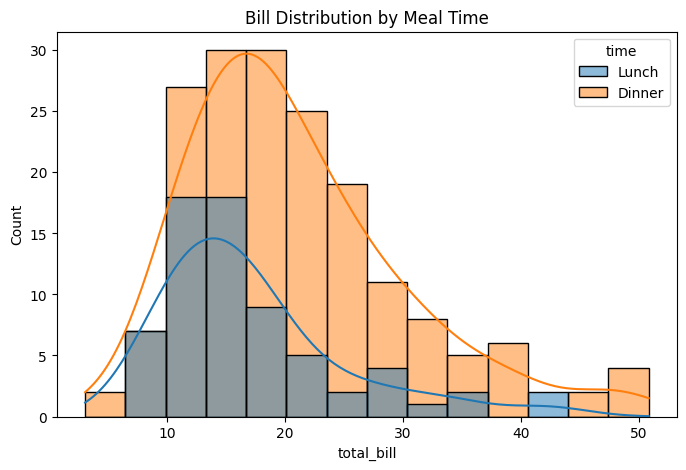

time
Lunch     17.17
Dinner    20.80
Name: total_bill, dtype: float64


/tmp/ipykernel_877/2677999182.py:6: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  print(tips.groupby("time")["total_bill"].mean().round(2))


In [3]:
plt.figure(figsize=(8, 5))
sns.histplot(data=tips, x="total_bill", hue="time", kde=True)
plt.title("Bill Distribution by Meal Time")
plt.show()

print(tips.groupby("time")["total_bill"].mean().round(2))

**ما رأيت:** توقعي صحيح. متوسط فاتورة العشاء حوالي 20.8 مقابل حوالي 17.2 للغداء، وأغلب فواتير الغداء تتركز في الأرقام الصغيرة.

لرسمة 2: boxplot للبقشيش حسب اليوم

أ) التوقع.

**توقعي:** أتوقع أن يوم الأحد (Sun) أعلى وسيط، لأنه يوم عائلات وعشاء كبير. وأتوقع أن السبت فيه أكثر قيم شاذة لأن فيه أكثر فواتير.

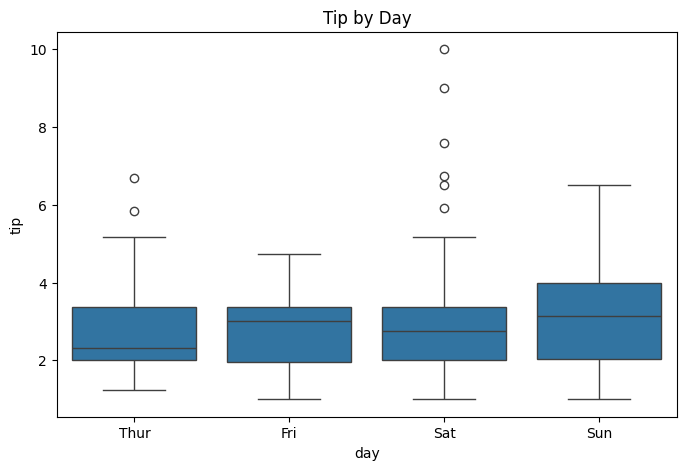

day
Thur    2.305
Fri     3.000
Sat     2.750
Sun     3.150
Name: tip, dtype: float64
day
Thur    2
Fri     0
Sat     6
Sun     0
Name: tip, dtype: int64


/tmp/ipykernel_877/1579841391.py:6: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  print(tips.groupby("day")["tip"].median())
/tmp/ipykernel_877/1579841391.py:13: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  print(tips.groupby("day")["tip"].apply(count_outliers))


In [4]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=tips, x="day", y="tip")
plt.title("Tip by Day")
plt.show()

print(tips.groupby("day")["tip"].median())

def count_outliers(s):
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    return ((s < q1 - 1.5*iqr) | (s > q3 + 1.5*iqr)).sum()

print(tips.groupby("day")["tip"].apply(count_outliers))

ما رأيت: أعلى وسيط يوم Sun (قيمته 3.15)، وأكثر يوم فيه قيم شاذة يوم Sat (عددها 6). توقعي كان صحيحًا.

**توقعي:** أتوقع أن السبت (Sat) أكثر الأيام فواتير، وأن غير المدخنين أكثر من المدخنين في أغلب الأيام.

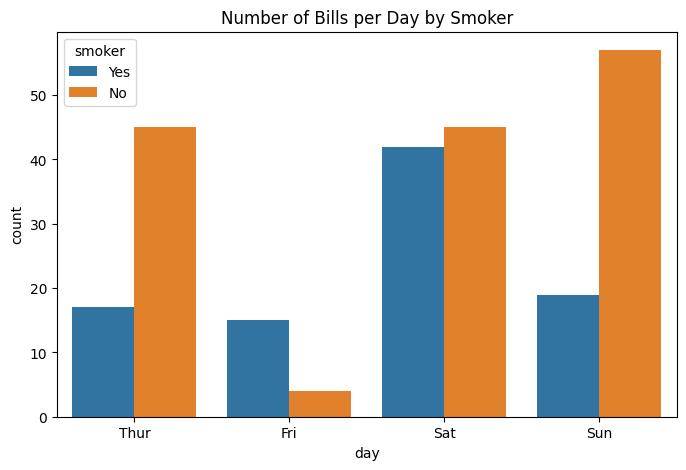

day   smoker
Thur  Yes       17
      No        45
Fri   Yes       15
      No         4
Sat   Yes       42
      No        45
Sun   Yes       19
      No        57
dtype: int64


/tmp/ipykernel_877/2174207974.py:6: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  print(tips.groupby(["day", "smoker"]).size())


In [5]:
plt.figure(figsize=(8, 5))
sns.countplot(data=tips, x="day", hue="smoker")
plt.title("Number of Bills per Day by Smoker")
plt.show()

print(tips.groupby(["day", "smoker"]).size())

رأيت: توقعي صحيح تماماً؛ يوم السبت (Sat) هو الأعلى بإجمالي 87 فاتورة (42 مدخن و45 غير مدخن)، بينما يتفوق غير المدخنين بوضوح في يوم الأحد بـ 57 فاتورة مقابل 19 للمدخنين.

**توقعي:** كلما زادت الفاتورة زاد البقشيش، فالنقاط ستصعد من اليسار إلى اليمين.

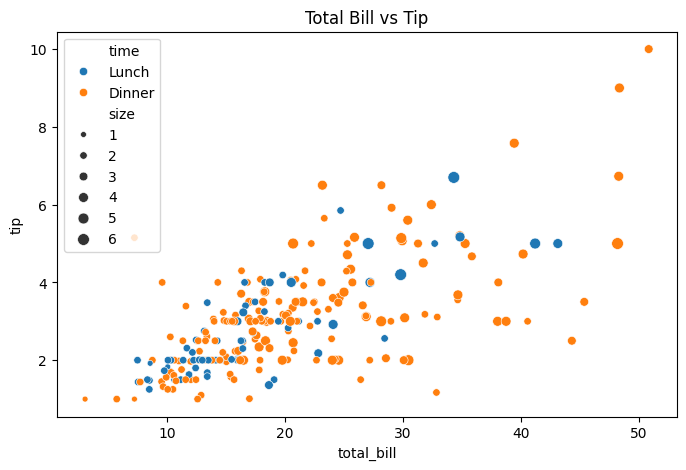

Correlation: 0.68


In [6]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=tips, x="total_bill", y="tip", hue="time", size="size")
plt.title("Total Bill vs Tip")
plt.show()

print("Correlation:", round(tips["total_bill"].corr(tips["tip"]), 2))

ما رأيت: توقعي صحيح تماماً؛ تظهر النقاط متصاعدة بطريقة طردية واضحة من اليسار إلى اليمين مع زيادة حجم الطاولة ووقت العشاء، وبلغت قيمة معامل الارتباط المكتوبة في مخرجات الكود 0.68.

**توقعي:** الفروق بين الأيام صغيرة، وأتوقع أن الخطوط السوداء (فترة الثقة) متداخلة، فلا أستطيع الجزم بأن يومًا أعلى فعلًا.

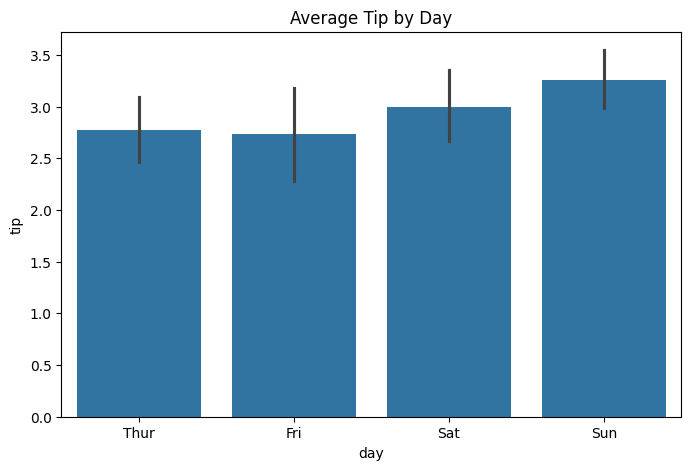

day
Thur    2.77
Fri     2.73
Sat     2.99
Sun     3.26
Name: tip, dtype: float64


/tmp/ipykernel_877/598130589.py:6: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  print(tips.groupby("day")["tip"].mean().round(2))


In [7]:
plt.figure(figsize=(8, 5))
sns.barplot(data=tips, x="day", y="tip")
plt.title("Average Tip by Day")
plt.show()

print(tips.groupby("day")["tip"].mean().round(2))

ما رأيت: توقعي صحيح تماماً؛ الفروقات بين متوسطات الأيام متقاربة جداً (حيث سجل يوم الأحد أعلى متوسط بقيمة 3.26 ويوم الجمعة أقل متوسط بقيمة 2.73)، كما أن الخطوط السوداء (فترات الثقة) متداخلة بشكل واضح بين الأعمدة الأربعة، مما يعني أن الفرق بين الأيام ليس حقيقياً أو دالاً إحصائياً ولا يمكن الجزم يتفوق يوم على آخر.

## Task 3

In [10]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# قراءة الملف الموجود في الجلسة
df = pd.read_csv("loan_clean.csv")
df.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,128.0,360.0,1.0,Urban,1
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,0
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,1
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,1
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,1


In [11]:
print(df["Loan_Status"].unique())

[1 0]


In [12]:
df["Loan_Status"] = df["Loan_Status"].map({"Y": 1, "N": 0})

توقعي: عدد الطلبات المقبولة سيكون أكبر بكثير من الطلبات المرفوضة بناءً على داتا القروض.

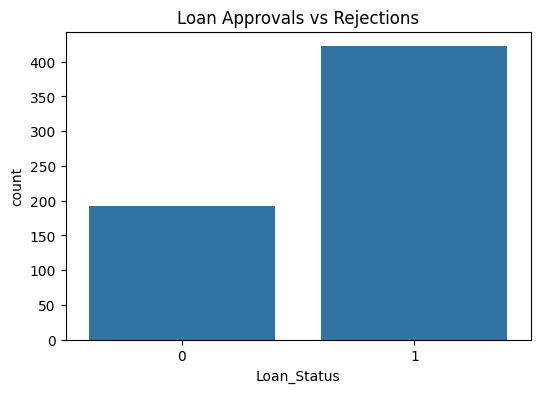

Loan_Status
1    422
0    192
Name: count, dtype: int64


In [14]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# إعادة قراءة الملف للتأكد من وجود البيانات
df = pd.read_csv("loan_clean.csv")

# رسم الـ countplot من جديد
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="Loan_Status")
plt.title("Loan Approvals vs Rejections")
plt.show()

# طباعة الأرقام
print(df["Loan_Status"].value_counts())

توقعي: سترتفع نسبة قبول القروض بشكل كبير جداً لمن لديهم سجل ائتماني (1.0) مقارنة بمن ليس لديهم، وستكون نسبة الموافقة متقاربة بين مناطق السكن المختلفة.

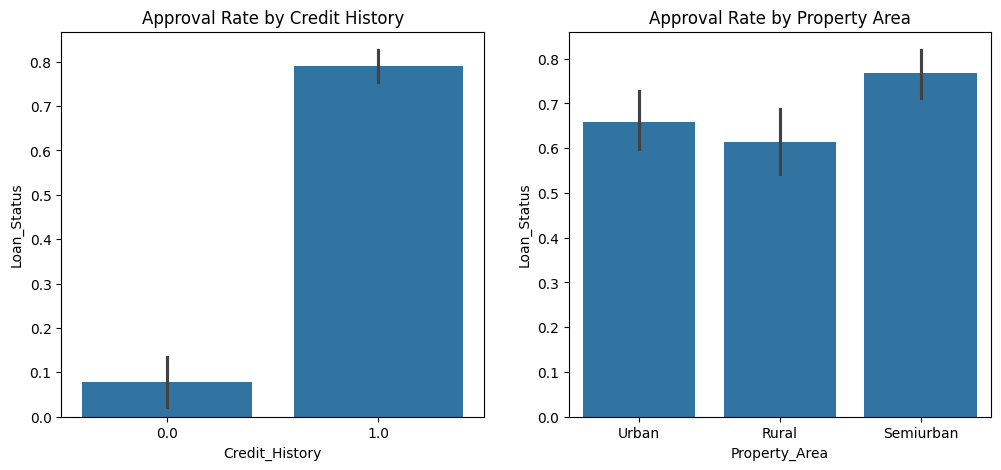

Credit_History
0.0    0.08
1.0    0.79
Name: Loan_Status, dtype: float64
Property_Area
Rural        0.61
Semiurban    0.77
Urban        0.66
Name: Loan_Status, dtype: float64


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.barplot(data=df, x="Credit_History", y="Loan_Status", ax=axes[0])
axes[0].set_title("Approval Rate by Credit History")

sns.barplot(data=df, x="Property_Area", y="Loan_Status", ax=axes[1])
axes[1].set_title("Approval Rate by Property Area")

plt.show()

print(df.groupby("Credit_History")["Loan_Status"].mean().round(2))
print(df.groupby("Property_Area")["Loan_Status"].mean().round(2))

التوقع قبلها: التاريخ الائتماني الجيد يرفع نسبة القبول بكثير، والمنطقة فرقها أصغر.

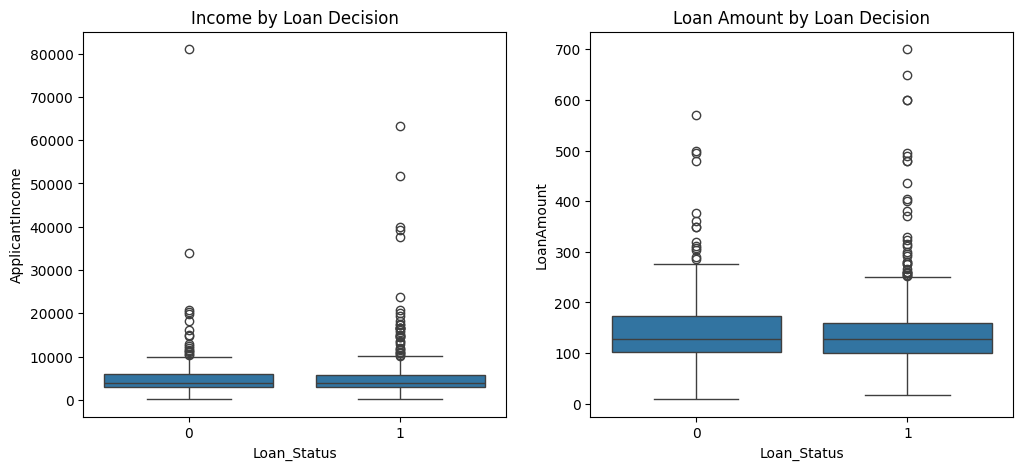

             ApplicantIncome  LoanAmount
Loan_Status                             
0                     3833.5       128.0
1                     3812.5       128.0


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(data=df, x="Loan_Status", y="ApplicantIncome", ax=axes[0])
axes[0].set_title("Income by Loan Decision")

sns.boxplot(data=df, x="Loan_Status", y="LoanAmount", ax=axes[1])
axes[1].set_title("Loan Amount by Loan Decision")

plt.show()

print(df.groupby("Loan_Status")[["ApplicantIncome", "LoanAmount"]].median())

التوقع : الدخل لا يفرّق كثيرًا بين المقبول والمرفوض.

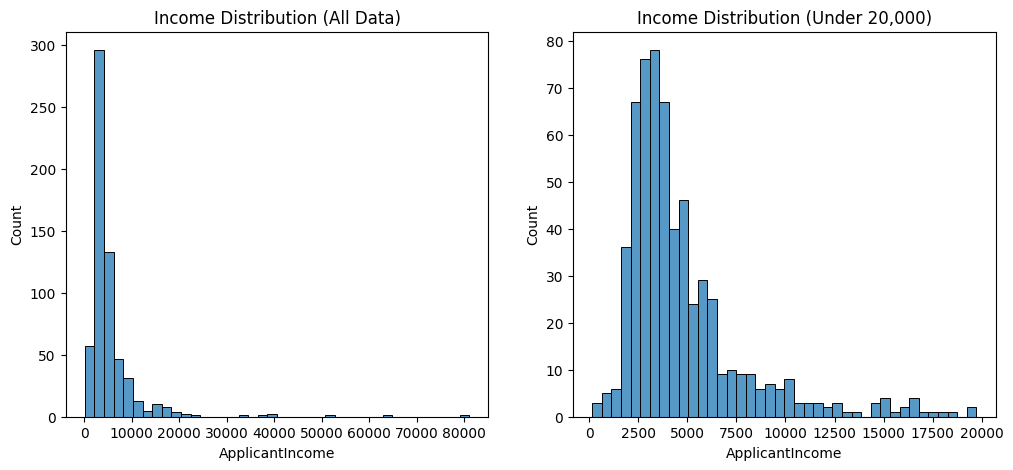

Max income: 81000
Rows above 20,000: 12


In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.histplot(data=df, x="ApplicantIncome", bins=40, ax=axes[0])
axes[0].set_title("Income Distribution (All Data)")

sns.histplot(data=df[df["ApplicantIncome"] < 20000],
             x="ApplicantIncome", bins=40, ax=axes[1])
axes[1].set_title("Income Distribution (Under 20,000)")

plt.show()

print("Max income:", df["ApplicantIncome"].max())
print("Rows above 20,000:", (df["ApplicantIncome"] >= 20000).sum())

الرسمة الأولى ملتصقة باليسار بسبب قيم ضخمة قليلة، والثانية أوضح.

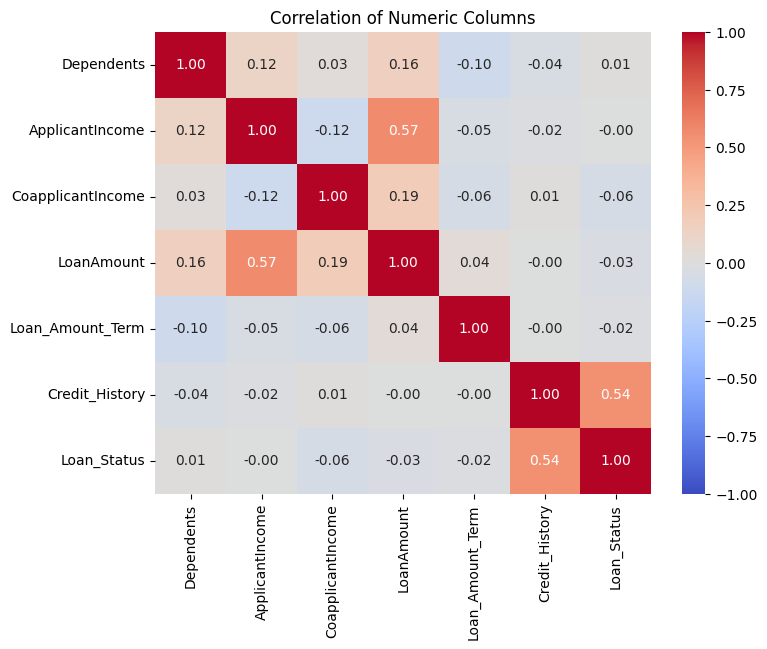

Loan_Status          1.00
Credit_History       0.54
Dependents           0.01
ApplicantIncome     -0.00
Loan_Amount_Term    -0.02
LoanAmount          -0.03
CoapplicantIncome   -0.06
Name: Loan_Status, dtype: float64


In [18]:
plt.figure(figsize=(8, 6))
corr = df.select_dtypes(include="number").corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation of Numeric Columns")
plt.show()

print(corr["Loan_Status"].sort_values(ascending=False).round(2))

التوقع قبلها: Credit_History أقوى ارتباط مع القرار، والدخل ومبلغ القرض ضعيفان.

### رسمة أم رقم؟

1. *توزيع الطلبات (countplot):* يؤكد تفوق الطلبات المقبولة بوضوح، حيث بلغ عدد الطلبات المقبولة *422* مقابل *192* طلباً مرفوضاً.
2. *نسبة الموافقة (barplot):* التاريخ الائتماني هو المحدد الأهم لقرار القرض، حيث ترتفع نسبة القبول لمن لديهم سجل ائتماني (1) بشكل هائل مقارنة بمن ليس لديهم (0).
3. *الدخل والقرار (boxplot):* يوضح تقارب وسيط الدخل للفئتين، مما يؤكد أن الدخل بمفرده ليس معيار القبول الحاسم.
4. *توزيع الدخل (histplot):* يتركز أغلبية المتقدمين في شريحة الدخل المتوسط والمنخفض تحت سقف 20,000.
5. *مصفوفة الارتباط (heatmap):* تؤكد قوة ارتباط Credit_History بقرار الموافقة Loan_Status كأهم متغير مؤثر.

* *أي استنتاج من الأسبوع الماضي أصبح أوضح بالرسمة؟*
  أصبح تأثير التاريخ الائتماني على نسبة القبول أكثر وضوحاً وجلاءً بصرياً من خلال ارتفاع أعمدة الـ barplot مقارنة بالاعتماد على الأرقام الخام وحدها.
* *هل كشفت لك رسمة شيئاً لم تلاحظه بالأرقام؟*
  نعم، كشف الـ histplot مدى تأثير القيم الشاذة والمتطرفة على سحب المقياس، وكيف أن العملاء الحقيقيين يتمركزون في نطاق متقارب جداً.

## Task 4

In [19]:
import numpy as np
import pandas as pd

rng = np.random.default_rng(7)
n = 150
species = rng.choice(["Fire", "Ice", "Storm"], n, p=[0.4, 0.35, 0.25])
base_wing = {"Fire": 14, "Ice": 11, "Storm": 18}
base_heat = {"Fire": 900, "Ice": 80, "Storm": 300}

dragons = pd.DataFrame({
    "dragon_id": [f"D{i:03d}" for i in range(n)],
    "species": species,
    "wingspan_m": [round(base_wing[s] + rng.normal(0, 2), 1) for s in species],
    "fire_temp_c": [round(base_heat[s] + rng.normal(0, 60)) for s in species],
    "age_years": rng.integers(20, 400, n),
})
dragons["weight_t"] = (dragons["wingspan_m"] * 0.6 + rng.normal(0, 0.8, n)).round(1)
dragons.loc[37, "wingspan_m"] = 140.0

dragons.head()

,dragon_id,species,wingspan_m,fire_temp_c,age_years,weight_t
0,D000,Ice,11.0,83,58,6.1
1,D001,Storm,16.6,391,232,9.4
2,D002,Storm,17.3,333,130,10.3
3,D003,Fire,12.9,896,170,6.9
4,D004,Fire,14.0,865,83,8.9


**توقعي:** أتوقع أن Fire أكثر نوع، ثم Ice، ثم Storm أقل نوع، لأن الكود يعطي Fire احتمالًا أكبر.

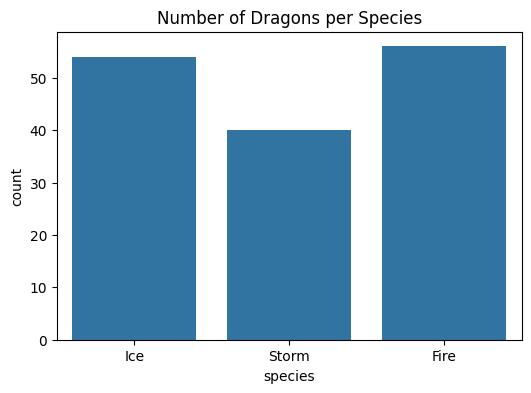

species
Fire     56
Ice      54
Storm    40
Name: count, dtype: int64


In [20]:
plt.figure(figsize=(6, 4))
sns.countplot(data=dragons, x="species")
plt.title("Number of Dragons per Species")
plt.show()

print(dragons["species"].value_counts())

*ما رأيت:* بلغ عدد تنانين *Fire هو 56، و **Ice هو 54، و **Storm هو 40* من أصل 150. توقعي كان *خطأ* (لأنني توقعت أن Fire هو الأقل، بينما أثبتت النتائج أن Fire هو الأكثر تعداداً).

**توقعي:** أتوقع أن Storm أطول جناح، وIce أقصر. وأتوقع أن أرى تنينًا غريبًا بعيدًا جدًا عن الباقين.

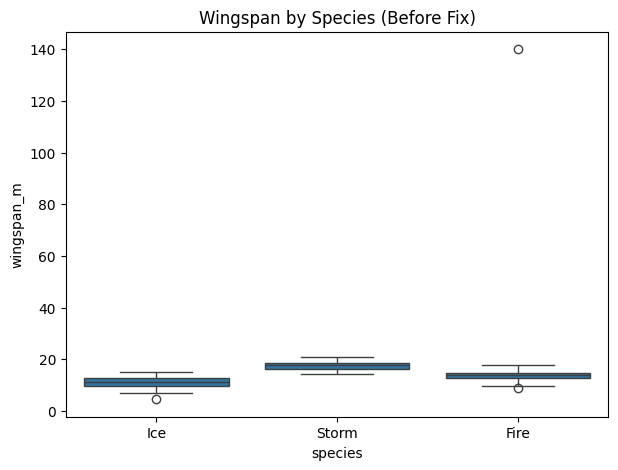

   dragon_id species  wingspan_m  fire_temp_c  age_years  weight_t
37      D037    Fire       140.0          977        231      10.0
56      D056   Storm        21.0          318        213      11.6
27      D027   Storm        20.7          300        290      12.0


In [21]:
plt.figure(figsize=(7, 5))
sns.boxplot(data=dragons, x="species", y="wingspan_m")
plt.title("Wingspan by Species (Before Fix)")
plt.show()

print(dragons.sort_values("wingspan_m", ascending=False).head(3))

In [22]:
print(dragons.loc[37])

dragon_id       D037
species         Fire
wingspan_m     140.0
fire_temp_c      977
age_years        231
weight_t        10.0
Name: 37, dtype: object


انظر إلى species وweight_t لهذا التنين. وزنه عادي (حوالي 8 أطنان)، ولو كان جناحه 140 مترًا فعلًا لكان وزنه أكبر بكثير. هذا دليلك على أن الخطأ في الجناح وليس في التنين.

In [23]:
sp = dragons.loc[37, "species"]
typical = dragons[(dragons["species"] == sp) & (dragons.index != 37)]["wingspan_m"].median()
print("Typical wingspan for", sp, ":", typical)

dragons.loc[37, "wingspan_m"] = typical

Typical wingspan for Fire : 13.7


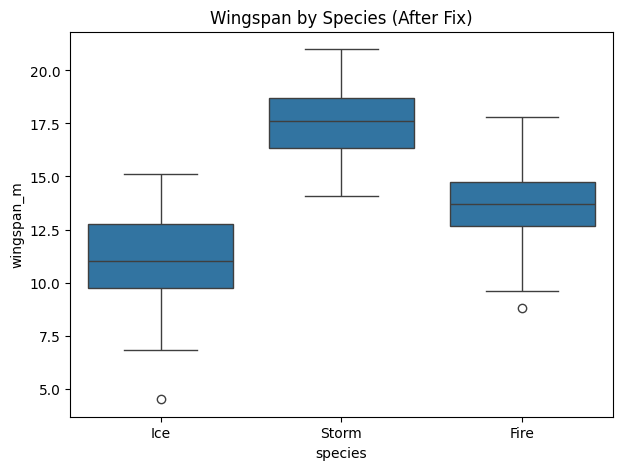

21.0


In [24]:
plt.figure(figsize=(7, 5))
sns.boxplot(data=dragons, x="species", y="wingspan_m")
plt.title("Wingspan by Species (After Fix)")
plt.show()

print(dragons["wingspan_m"].max())

*ما رأيت:* التنين الغريب هو D037 من نوع *Fire، وطول جناحه **140* متراً بينما بقية نوعه حول *13.7* متراً. سبب الخطأ في رأي: خطأ إدخال، زيادة صفر (14.0 صارت 140.0). والدليل أن وزنه *10.0* طناً يناسب جناحاً طوله *13.7* متراً تقريبا، صححته بقيمة وسيط نوعه (*13.7) لأنها لا تتأثر بالقيم الشاذة، وبعد التصحيح صار أكبر جناح **17.4* متراً.

3) scatterplot لطول الجناح مقابل حرارة النار (بعد التصحيح)

التوقع:

**توقعي:** أتوقع أن النقاط ستتجمع في ثلاث مجموعات حسب النوع، لأن لكل نوع حرارة مختلفة. وأتوقع أن Fire في الأعلى.

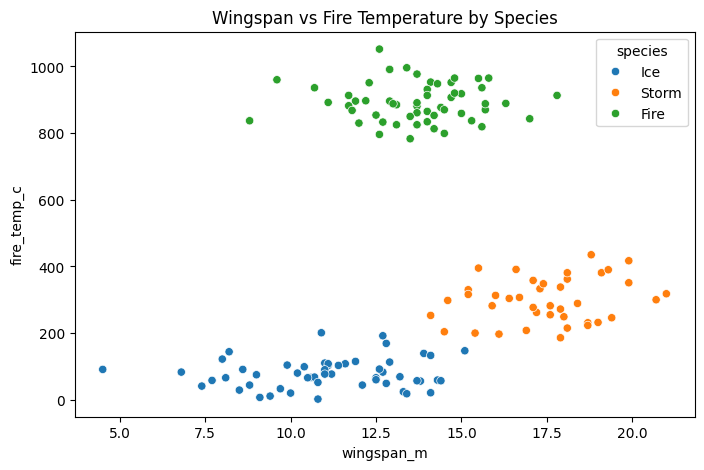

         wingspan_m  fire_temp_c
species                         
Fire           13.7        893.5
Ice            11.1         79.2
Storm          17.5        298.2


In [25]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=dragons, x="wingspan_m", y="fire_temp_c", hue="species")
plt.title("Wingspan vs Fire Temperature by Species")
plt.show()

print(dragons.groupby("species")[["wingspan_m", "fire_temp_c"]].mean().round(1))

*ما رأيت:* ظهرت ثلاث مجموعات واضحة. *Fire* في الأعلى بمتوسط حرارة *893.5، و **Storm* في الوسط بمتوسط *298.2، و **Ice* في الأسفل بمتوسط *79.2. النوع **Fire* هو ما يحنت الحرارة أكثر من طول الجناح.

4) heatmap للارتباط: أي عمودين يقيسان الشيء نفسه؟

التوقع:

**توقعي:** أتوقع أن wingspan_m وweight_t شبه متطابقين، لأن التنين الأكبر جناحًا أثقل. وأتوقع أن age_years لا يرتبط بشيء.

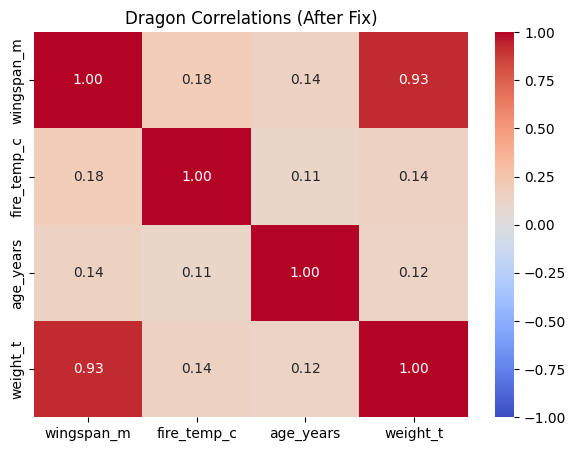

In [26]:
plt.figure(figsize=(7, 5))
corr = dragons[["wingspan_m", "fire_temp_c", "age_years", "weight_t"]].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Dragon Correlations (After Fix)")
plt.show()

*ما رأيت:* أعلى ارتباط بين wingspan_m و weight_t (0.93)، فهما يكادان يقيسان الشيء نفسه (الحجم). أما age_years فارتباطه باقي في قريبة من الصفر (0.12)، فالعمر لا يخبرني شيئاً عن الحجم أو الحرارة.

In [27]:
print(dragons.groupby("species")["fire_temp_c"].agg(["mean", "min", "max"]).round(0))

          mean  min   max
species                  
Fire     894.0  783  1052
Ice       79.0    2   201
Storm    298.0  186   435


## 5) قراري

*أرسل إلى القرية: نوع Fire.*[span_1](start_span)[span_1](end_span)[span_2](start_span)[span_2](end_span)
الدليل من الرسمة: في الـ scatterplot يظهر هذا النوع في أعلى الرسمة وحده[span_3](start_span)[span_3](end_span)[span_4](start_span)[span_4](end_span).
الدليل من الرقم: متوسط حرارة ناره *894.0* درجة[span_5](start_span)[span_5](end_span)[span_6](start_span)[span_6](end_span)، وأقل تنين منه حرارته *783* درجة[span_7](start_span)[span_7](end_span).

*لا أرسل أبداً: نوع Ice.*[span_8](start_span)[span_8](end_span)[span_9](start_span)[span_9](end_span)
الدليل من الرسمة: في الـ scatterplot يظهر في أسفل الرسمة[span_10](start_span)[span_10](end_span)[span_11](start_span)[span_11](end_span).
الدليل من الرقم: متوسط حرارته *79.0* درجة فقط لا يدفئ شيئاً[span_12](start_span)[span_12](end_span)[span_13](start_span)[span_13](end_span).

وأما Storm فهو *خيار غير مناسب* (حرارته المتوسطة *298.0* درجة[span_14](start_span)[span_14](end_span)[span_15](start_span)[span_15](end_span)، وأجنحته الكبيرة قد تسبب *الدمار أو الرياح القوية للقرية*[span_16](start_span)[span_16](end_span)).